In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual plot style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Load dataset provided by Anmol
df = pd.read_excel("traffic_dataset_1000_combined.xlsx")

print("Dataset Shape:", df.shape)
df.head(3)

Dataset Shape: (1000, 22)


,reading_id,source_record_id,road_id,road_code,road_name,road_description,sensor_id,sensor_code,sensor_name,sensor_type,...,timestamp,vehicle_count,vehicle_capacity,density,congestion_level,previous_congestion_level,congestion_changed,effective_from,effective_to,created_at
0,261,1000261,3,JCT-003,Junction 3,Monitored road segment at Junction 3,3,SEN-J3-01,Junction 3 Counter,SIMULATED,...,2026-01-01 03:08:00,7,40,0.18,LOW,LOW,False,2026-01-01,2026-12-31 23:59:00,2026-01-01 03:08:00
1,525,1000525,4,JCT-004,Junction 4,Monitored road segment at Junction 4,4,SEN-J4-01,Junction 4 Counter,SIMULATED,...,2026-01-01 06:13:00,13,20,0.65,HIGH,HIGH,False,2026-01-01,2026-12-31 23:59:00,2026-01-01 06:14:00
2,830,1000830,2,JCT-002,Junction 2,Monitored road segment at Junction 2,2,SEN-J2-01,Junction 2 Counter,SIMULATED,...,2026-01-01 07:57:00,33,40,0.82,SEVERE,SEVERE,False,2026-01-01,2026-12-31 23:59:00,2026-01-01 07:57:00


In [2]:
# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Feature Engineering: Extract temporal clues (SRS Day 1 & Day 2 requirements)
df['hour_of_day'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_name()
# Peak hours: Morning 07:00-10:00, Evening 17:00-20:00
df['is_peak_hour'] = df['hour_of_day'].apply(lambda h: True if (7 <= h <= 10 or 17 <= h <= 20) else False)

# Check missing values across all columns
print("Total missing values in dataset:", df.isnull().sum().sum())
print("\nPreview engineered features:")
df[['timestamp', 'road_id', 'vehicle_count', 'density', 'hour_of_day', 'is_peak_hour', 'congestion_level']].head(5)

Total missing values in dataset: 0

Preview engineered features:


,timestamp,road_id,vehicle_count,density,hour_of_day,is_peak_hour,congestion_level
0,2026-01-01 03:08:00,3,7,0.18,3,False,LOW
1,2026-01-01 06:13:00,4,13,0.65,6,False,HIGH
2,2026-01-01 07:57:00,2,33,0.82,7,True,SEVERE
3,2026-01-01 09:15:00,1,66,0.66,9,True,HIGH
4,2026-01-01 09:38:00,1,55,0.55,9,True,MEDIUM


Density Thresholds by Congestion Level:

                  count   min      mean   max
congestion_level                             
HIGH                175  0.61  0.699829  0.80
LOW                 235  0.01  0.184979  0.29
MEDIUM              555  0.30  0.445514  0.60
SEVERE               35  0.81  0.879143  1.00


C:\Users\saksham\AppData\Local\Temp\ipykernel_4052\2683662551.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='congestion_level', order=['LOW', 'MEDIUM', 'HIGH', 'SEVERE'], palette='viridis')


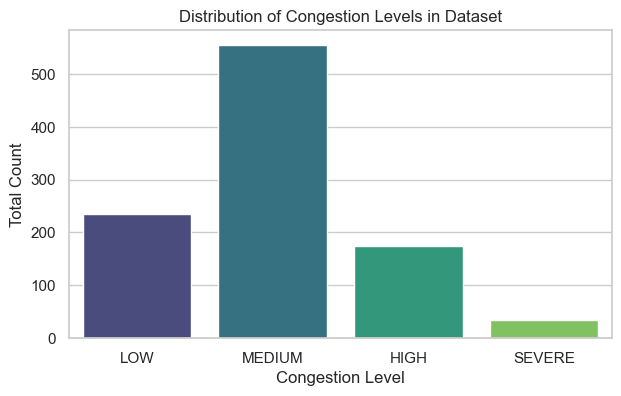

In [3]:
# Aggregate density statistics grouped by congestion level
density_stats = df.groupby('congestion_level')['density'].agg(['count', 'min', 'mean', 'max'])
print("Density Thresholds by Congestion Level:\n")
print(density_stats)

# Plot distribution of congestion levels
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='congestion_level', order=['LOW', 'MEDIUM', 'HIGH', 'SEVERE'], palette='viridis')
plt.title("Distribution of Congestion Levels in Dataset")
plt.xlabel("Congestion Level")
plt.ylabel("Total Count")
plt.show()

Hourly Congestion Breakdown (0-23 hrs):

congestion_level  HIGH  LOW  MEDIUM  SEVERE
hour_of_day                                
0                    0   25      12       0
1                    0   11      13       0
2                    0   28      13       0
3                    0   39      17       0
4                    0   22      12       0
5                    0   34      21       0
6                    1    8      31       1
7                   19    0      17       8
8                   22    0      20       5
9                   21    0      23       1
10                  16    0      26       4
11                   2    5      29       0
12                   6    4      26       0
13                   4    5      34       0
14                   1   11      36       0
15                   6   14      37       0
16                   2   10      35       1
17                  19    0      10       5
18                  11    0      20       4
19                  18    0      11

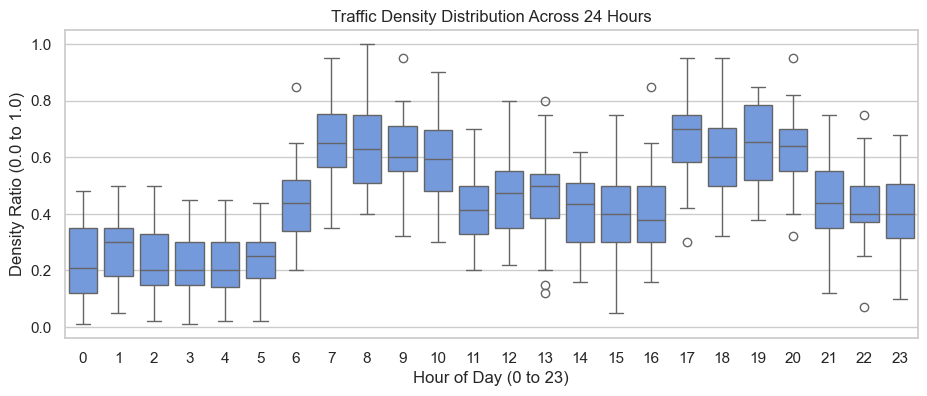

In [4]:
# Cross-tabulate hour of day with congestion level
hourly_crosstab = pd.crosstab(df['hour_of_day'], df['congestion_level'])
print("Hourly Congestion Breakdown (0-23 hrs):\n")
print(hourly_crosstab)

# Plot hourly density distribution using a boxplot
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x='hour_of_day', y='density', color='cornflowerblue')
plt.title("Traffic Density Distribution Across 24 Hours")
plt.xlabel("Hour of Day (0 to 23)")
plt.ylabel("Density Ratio (0.0 to 1.0)")
plt.show()

Road Segment Summary Table:

   road_id   road_name  vehicle_capacity  total_records  avg_vehicles  \
0        1  Junction 1               100            319     43.172414   
1        2  Junction 2                40            240     18.829167   
2        3  Junction 3                40            242     14.338843   
3        4  Junction 4                20            199     10.713568   

   max_vehicles  avg_density  max_density  
0            83     0.431724         0.83  
1            38     0.470667         0.95  
2            32     0.358223         0.80  
3            20     0.535678         1.00  


C:\Users\saksham\AppData\Local\Temp\ipykernel_4052\3192468084.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=road_summary, x='road_name', y='avg_density', palette='crest')


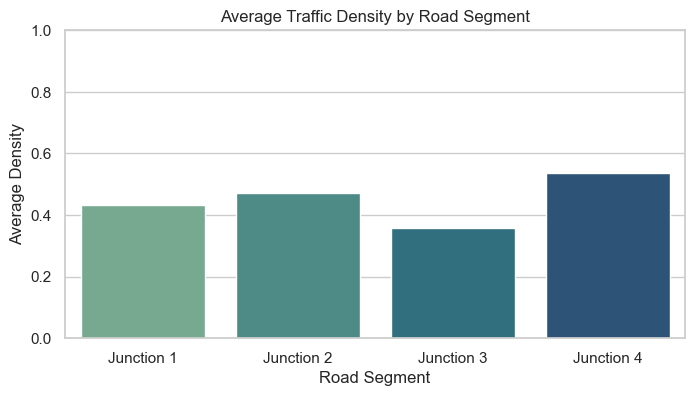

In [5]:
# Road-level summary: capacity, vehicle volume, and density across junctions
road_summary = df.groupby(['road_id', 'road_name', 'vehicle_capacity']).agg(
    total_records=('reading_id', 'count'),
    avg_vehicles=('vehicle_count', 'mean'),
    max_vehicles=('vehicle_count', 'max'),
    avg_density=('density', 'mean'),
    max_density=('density', 'max')
).reset_index()

print("Road Segment Summary Table:\n")
print(road_summary)

# Plot average vs max density per road segment
plt.figure(figsize=(8, 4))
sns.barplot(data=road_summary, x='road_name', y='avg_density', palette='crest')
plt.title("Average Traffic Density by Road Segment")
plt.xlabel("Road Segment")
plt.ylabel("Average Density")
plt.ylim(0, 1.0)
plt.show()